# EDA-16-10: объединённый разведочный анализ данных

Дата: 2026-10-16. Цель — рассмотреть все 14 полей кейса 1 и
подготовить обоснование входов перед логистической регрессией.
Модели в этой тетради не обучаются.

Объединены [основной EDA](../01_eda.ipynb) и две близкие версии
работы участников: [Т1](<../team work/LLM_project.ipynb>) и
[Т2](<../team work/LLM_project_(2).ipynb>). Сохранены анализ
крайних значений и рисков утечки участников; добавлены недостающие
проверки и общий групповой протокол. Исходные файлы не изменяются.
Источники отдельных разделов указаны ниже; разбор ограничений — в
[TEAM_EDA_FINDINGS.md](../../TEAM_EDA_FINDINGS.md).

**Границы выводов.** Участники уже исследовали целевые связи по всему
CSV. Новый протокол не отменяет эту историю и не превращает данные
в ранее не изученную тестовую выборку. В текущем EDA связи с целями
рассчитываются только на train; validation используется для проверки
входных распределений. Значения тестовых целей не выводятся.

Авторы исходных командных тетрадей не указаны. Итоговое распределение
вклада участники должны подтвердить отдельно. Критерии готовности:
последовательное выполнение, проверенный CSV и состав выборок,
анализ всех полей, сохранённые факты и открытые решения.

## 1. Окружение, конфигурация и журнал событий

Запускать из каталога этой тетради в ядре `.venv` Python 3.11.
Корень проекта явно задаётся как `../..`; автоматического поиска
данных и установки библиотек из ячеек нет. Конфигурация —
[configs/eda_16_10.json](../../configs/eda_16_10.json).
Каждый запуск сохраняется отдельно. MLflow оставлен для будущих
модельных экспериментов; здесь используются `logging` и manifest.

In [1]:
import hashlib
import json
import logging
import platform
import sys
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

PROJECT_ROOT = Path("../..").resolve()
CONFIG_PATH = PROJECT_ROOT / "configs/eda_16_10.json"
assert CONFIG_PATH.is_file(), "Рабочий каталог — notebooks/eda/."
assert sys.version_info[:2] == (3, 11), "Нужен Python 3.11."
assert Path(sys.prefix).resolve() == PROJECT_ROOT / ".venv"
sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [2]:
from industrial_maintenance import data, eda, plots

%matplotlib inline
plots.setup_style()
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 100)

In [3]:
CONFIG = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
started_at = datetime.now(timezone.utc)
started_clock = perf_counter()
run_id = started_at.strftime("%Y%m%dT%H%M%S_%fZ")
output_root = PROJECT_ROOT / CONFIG["output_root"]
run_directory = output_root / "runs" / run_id
figure_directory = run_directory / "figures"
run_directory.mkdir(parents=True, exist_ok=False)
figure_directory.mkdir()

logger = logging.getLogger("industrial_maintenance.EDA-16-10")
for old_handler in list(logger.handlers):
    old_handler.close()
    logger.removeHandler(old_handler)
logger.setLevel(logging.INFO)
logger.propagate = False
formatter = logging.Formatter("%(asctime)s %(levelname)s %(message)s")
file_handler = logging.FileHandler(run_directory / "run.log", encoding="utf-8")
console_handler = logging.StreamHandler(sys.stdout)
for handler in [file_handler, console_handler]:
    handler.setFormatter(formatter)
    logger.addHandler(handler)

library_versions = {
    name: version(name)
    for name in [
        "pandas",
        "numpy",
        "scipy",
        "scikit-learn",
        "matplotlib",
        "seaborn",
        "nbformat",
        "nbclient",
    ]
}
manifest = {
    "analysis_id": CONFIG["analysis_id"],
    "run_id": run_id,
    "status": "running",
    "started_at_utc": started_at.isoformat(),
    "python": sys.version,
    "platform": platform.platform(),
    "libraries": library_versions,
    "config": CONFIG,
    "scope": "target associations: train; input comparison: train/val",
    "authors": "Авторство участников требует подтверждения",
}
manifest_path = run_directory / "manifest.json"
manifest_path.write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
(run_directory / "config.json").write_text(
    json.dumps(CONFIG, ensure_ascii=False, indent=2), encoding="utf-8"
)
logger.info("Начало EDA; run_id=%s", run_id)
display(pd.Series(library_versions, name="Версия"))
display(CONFIG)
tables = {}

2026-10-16 13:06:38,313 INFO Начало EDA; run_id=20261016T100638_301364Z


pandas           3.0.6
numpy            2.4.6
scipy           1.17.1
scikit-learn     1.9.1
matplotlib      3.11.2
seaborn         0.13.2
nbformat        5.11.1
nbclient        0.11.0
Name: Версия, dtype: str

{'analysis_id': 'EDA-16-10',
 'dataset': 'Data/Кейс_1_сложный_промышленность_15000.csv',
 'sha256': '1fa90ae0ac35681c435a4b34874faf51d41e9256c8c3c991a1dfdbf700511e07',
 'seed': 42,
 'split_version': 'eda_v1',
 'n_splits': 7,
 'test_fold': 0,
 'validation_fold': 1,
 'split_group': 'normalized_exact_operator_log',
 'output_root': 'artifacts/eda/EDA-16-10',
 'notebook': 'notebooks/eda/EDA-16-10.ipynb',
 'source_notebooks': ['notebooks/01_eda.ipynb',
  'notebooks/team work/LLM_project.ipynb',
  'notebooks/team work/LLM_project_(2).ipynb'],
 'numeric_columns': ['operating_hours',
  'temperature_c',
  'vibration_mm_s',
  'pressure_bar',
  'load_ratio',
  'horizon_days'],
 'categorical_columns': ['equipment',
  'manual_id',
  'severity',
  'required_route'],
 'targets': ['failure_within_30d', 'fault_type'],
 'min_token_documents': 10,
 'top_tokens': 10,
 'examples_per_class': 2,
 'top_categories_plot': 20,
 'iqr_multiplier': 1.5,
 'load_tolerance_percentage_points': 1.0,
 'comparison_quantile

## 2. Источник, схема и качество всех 14 полей

Источники: основной EDA, раздел 2; Т1/Т2, ячейки 2–3 и 15.
Полный CSV используется только для технической проверки и защиты
границ выборок: контрольная сумма, схема, пропуски, пустые строки,
бесконечные числа и повторы. Данные не исправляются автоматически.
Отсутствие пропусков не доказывает правильность физических значений.

In [4]:
df, source_manifest = data.load_dataset(PROJECT_ROOT, CONFIG)
assert df.index.equals(pd.RangeIndex(len(df)))
tables["source_quality"] = eda.quality_table(df)
tables["source_duplicates"] = data.duplicate_audit(df).to_frame()
numeric = CONFIG["numeric_columns"]
categorical = CONFIG["categorical_columns"]
targets = CONFIG["targets"]

display(pd.Series(source_manifest, name="Источник"))
display(tables["source_quality"])
display(tables["source_duplicates"])
numeric_values = df[numeric].to_numpy(dtype=float)
assert np.isfinite(numeric_values).all(), "Есть неверные числа."
assert not df["id"].str.strip().eq("").any(), "Есть пустой id."
assert not df["fault_type"].str.strip().eq("").any()
logger.info("Источник проверен: %s строк, %s полей", *df.shape)

dataset                                                           Data/Кейс_1_сложный_промышленность_15000.csv
sha256                                        1fa90ae0ac35681c435a4b34874faf51d41e9256c8c3c991a1dfdbf700511e07
rows                                                                                                     15000
columns    [id, equipment, operating_hours, temperature_c, vibration_mm_s, pressure_bar, load_ratio, operat...
bytes                                                                                                  3257589
Name: Источник, dtype: object

,Тип,Пропуски,Доля пропусков,Различные значения,Пустые строки,Бесконечные значения
Поле,,,,,,
id,string,0,0.0,15000,0,0
equipment,str,0,0.0,6,0,0
operating_hours,int64,0,0.0,2539,0,0
temperature_c,float64,0,0.0,3938,0,0
vibration_mm_s,float64,0,0.0,4787,0,0
pressure_bar,float64,0,0.0,4151,0,0
load_ratio,float64,0,0.0,651,0,0
operator_log,str,0,0.0,396,0,0
manual_id,str,0,0.0,90,0,0


,Число
Повторы всех полей без id,0
Повторы наблюдений по восьми полям,0
Различные operator_log,396
Повторные operator_log,14604
Различные тексты после маскирования чисел,6


2026-10-16 13:18:37,158 INFO Источник проверен: 15000 строк, 14 полей


## 3. Один сохраняемый протокол разбиения

Источник: основной EDA, раздел 3. Используется уже описанный
`eda_v1`: `StratifiedGroupKFold`, семь частей, одна test, одна
validation, остальные train. Группы — одинаковые `operator_log`
после приведения регистра и пробелов. Метки участвуют только в
приблизительной стратификации. Состав сохраняется по `id`;
существующее разбиение проверяется и не заменяется.

Строковое разбиение 70/15/15 из Т1/Т2 сюда не переносится: оно
допускает пересечение точных журналов. Тексты без чисел могут
повторяться и при нашем протоколе; это показывается отдельно.
Такой протокол не проверяет новые машины или будущий период.

In [5]:
membership, split_manifest = data.get_or_create_splits(
    PROJECT_ROOT, df, CONFIG
)
data.validate_splits(df, membership)
annotated = df.merge(membership, on="id", validate="one_to_one")
train = annotated.loc[annotated["split"].eq("train"), df.columns].copy()
validation = annotated.loc[
    annotated["split"].eq("validation"), df.columns
].copy()
tables["split_sizes"] = membership.groupby("split").agg(
    records=("id", "size"), groups=("group_id", "nunique")
)
tables["split_overlap"] = data.split_overlap_audit(df, membership)
assert tables["split_overlap"]["Общие id"].eq(0).all()
assert tables["split_overlap"]["Общие точные тексты"].eq(0).all()
assert set(train["id"]).isdisjoint(validation["id"])
display(tables["split_sizes"])
display(tables["split_overlap"])
display(Markdown(split_manifest["limitation"]))
logger.info("Разбиение проверено; для целевых связей train=%s", len(train))

,records,groups
split,,
test,2152,56
train,10655,281
validation,2193,59


,Пара выборок,Общие id,Общие точные тексты,Общие тексты без чисел
0,train / validation,0,0,6
1,train / test,0,0,6
2,validation / test,0,0,6


Общие тексты после маскирования чисел могут пересекать выборки. Это не временная проверка и не доказательство качества на неизвестных шаблонах или машинах.

2026-10-16 13:18:59,720 INFO Разбиение проверено; для целевых связей train=10655


## 4. Связанные наблюдения: дополнительная проверка

Дополнение к обеим работам. Проверяем совпадения наблюдений после
маскирования чисел в тексте и округления показаний. Число знаков
задано в конфигурации: например, часы округляются до сотен.
Это эвристический поиск кандидатов на ручную проверку, а не
физический допуск и не доказательство независимости записей.
Эталонные метки в расчёте этих кандидатов не участвуют.

In [6]:
rounded_columns = list(CONFIG["near_duplicate_rounding"])
rounded_observations = annotated[rounded_columns].round(
    CONFIG["near_duplicate_rounding"]
)
rounded_observations["equipment"] = annotated["equipment"]
rounded_observations["masked_log"] = annotated["operator_log"].map(
    lambda value: data.normalize_log(value, mask_numbers=True)
)
candidate_groups = pd.util.hash_pandas_object(
    rounded_observations, index=False
)
candidates = pd.DataFrame(
    {
        "id": annotated["id"],
        "split": annotated["split"],
        "candidate_group": candidate_groups,
    }
)
candidate_sizes = candidates.groupby("candidate_group").agg(
    records=("id", "size"), partitions=("split", "nunique")
)
repeated_groups = candidate_sizes.index[candidate_sizes["records"].gt(1)]
tables["near_duplicate_candidates"] = candidates.loc[
    candidates["candidate_group"].isin(repeated_groups)
].copy()
near_summary = pd.Series(
    {
        "Групп повторов после округления": len(repeated_groups),
        "Групп, пересекающих выборки": int(
            candidate_sizes["partitions"].gt(1).sum()
        ),
    }
)
tables["near_duplicate_summary"] = near_summary.to_frame("Число")
display(near_summary)
display(tables["near_duplicate_candidates"].head(20))

Групп повторов после округления    0
Групп, пересекающих выборки        0
dtype: int64

,id,split,candidate_group


## 5. Цели и подгруппы: только обучающая выборка

Источники: основной EDA, раздел 4; Т1/Т2, ячейки 3–4 и 11.
Показываем частоты и совместное распределение целей только на train.
`normal` и отсутствие отказа — разные определения; одна цель не
становится входом для другой. Тестовые метки здесь не исследуются.

### failure_within_30d: train

,Число,Доля
failure_within_30d,,
0,8870,0.832473
1,1785,0.167527


### fault_type: train

,Число,Доля
fault_type,,
normal,4783,0.448897
bearing_wear,1261,0.118348
overheat,1215,0.114031
seal_leak,1180,0.110746
imbalance,1147,0.107649
cavitation,1069,0.100328


### equipment: train

,Число,Доля
equipment,,
PN-200,1826,0.171375
CM-110,1802,0.169122
FV-40,1788,0.167809
PN-300,1767,0.165838
TR-90,1745,0.163773
CP-500,1727,0.162084


### severity: train

,Число,Доля
severity,,
low,7408,0.695260
medium,2639,0.247677
high,608,0.057062


failure_within_30d,0,1
fault_type,,
bearing_wear,784,477
cavitation,520,549
imbalance,977,170
normal,4783,0
overheat,776,439
seal_leak,1030,150


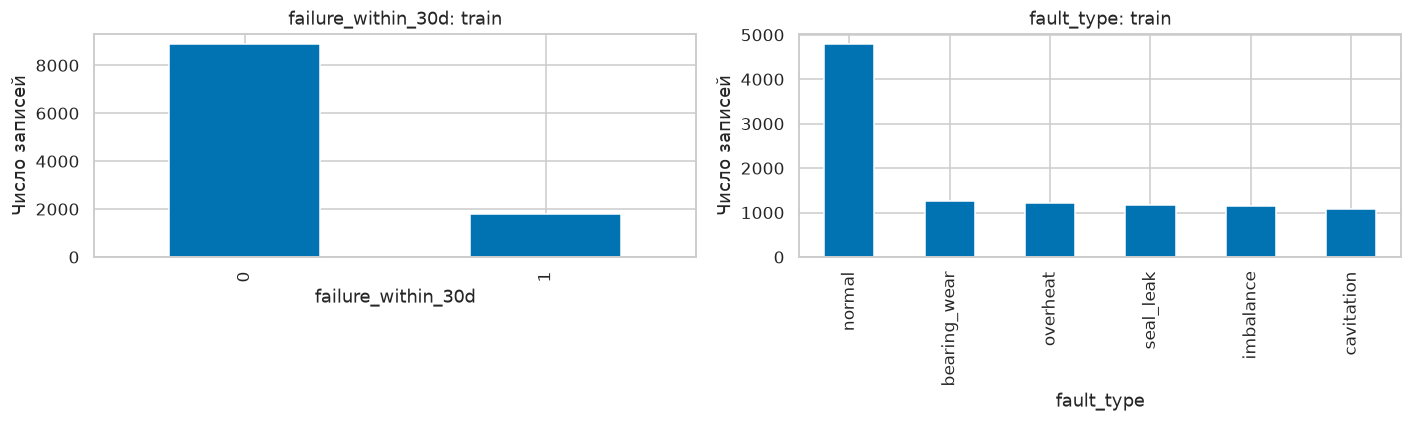

In [7]:
for field in targets + ["equipment", "severity"]:
    balance = eda.class_balance(train, field)
    tables[f"train_balance_{field}"] = balance
    display(Markdown(f"### {field}: train"))
    display(balance)
tables["train_target_relationship"] = pd.crosstab(
    train["fault_type"], train["failure_within_30d"]
)
display(tables["train_target_relationship"])

figure, axes = plt.subplots(1, 2, figsize=(13, 4))
for target, axis in zip(targets, axes):
    train[target].value_counts().plot.bar(ax=axis)
    axis.set_title(f"{target}: train")
    axis.set_xlabel(target)
    axis.set_ylabel("Число записей")
figure.tight_layout()
figure.savefig(figure_directory / "target_balance.png")
plt.show()
plt.close(figure)

## 6. Числовые поля: диапазоны и распределения

Источники: основной EDA, раздел 5; Т1/Т2, ячейка 5.
Анализируем пять показаний и `horizon_days`. Присутствие последнего
в EDA не означает разрешения использовать его как вход модели.
Наблюдаемые диапазоны не являются техническими нормативами.

,count,mean,std,min,1%,25%,50%,75%,99%,max
operating_hours,10655.0,1247.870389,693.332182,30.000,58.00000,643.5000,1246.000,1836.000,2544.9200,2699.000
temperature_c,10655.0,65.060629,10.469074,39.720,48.55000,58.5500,62.980,68.150,99.2922,118.760
vibration_mm_s,10655.0,2.975998,1.358167,0.101,1.02008,2.0070,2.537,3.737,6.7079,7.929
pressure_bar,10655.0,5.821375,1.020670,1.693,2.89454,5.3455,5.982,6.510,7.6900,8.593
load_ratio,10655.0,0.675927,0.186439,0.350,0.35900,0.5190,0.679,0.837,0.9910,1.000
horizon_days,10655.0,15.545565,8.588291,1.000,1.00000,8.0000,16.000,23.000,30.0000,30.000


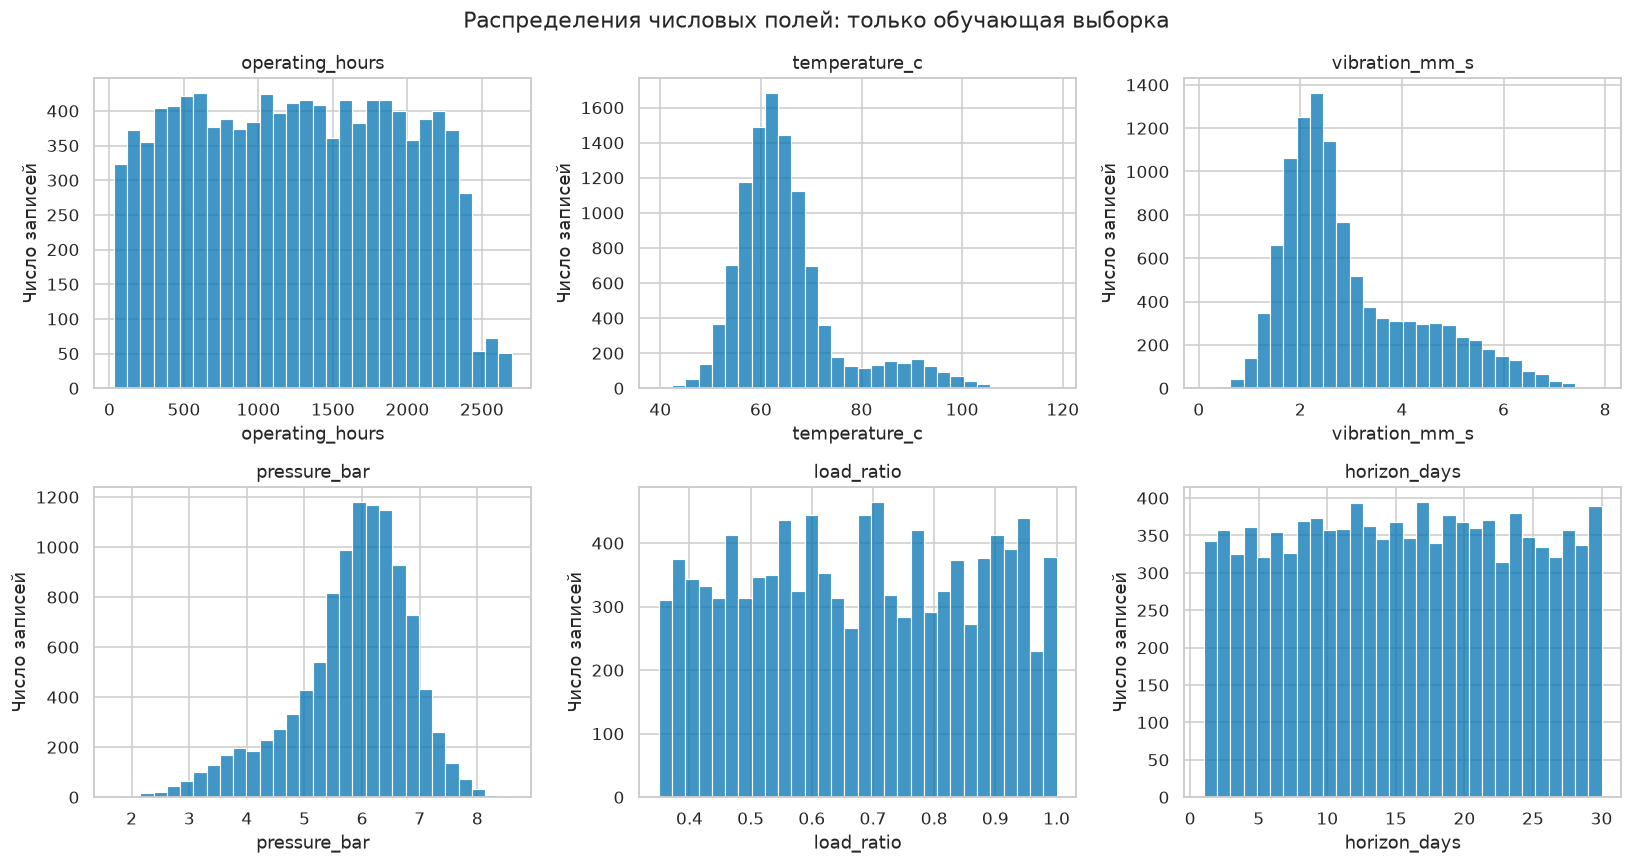

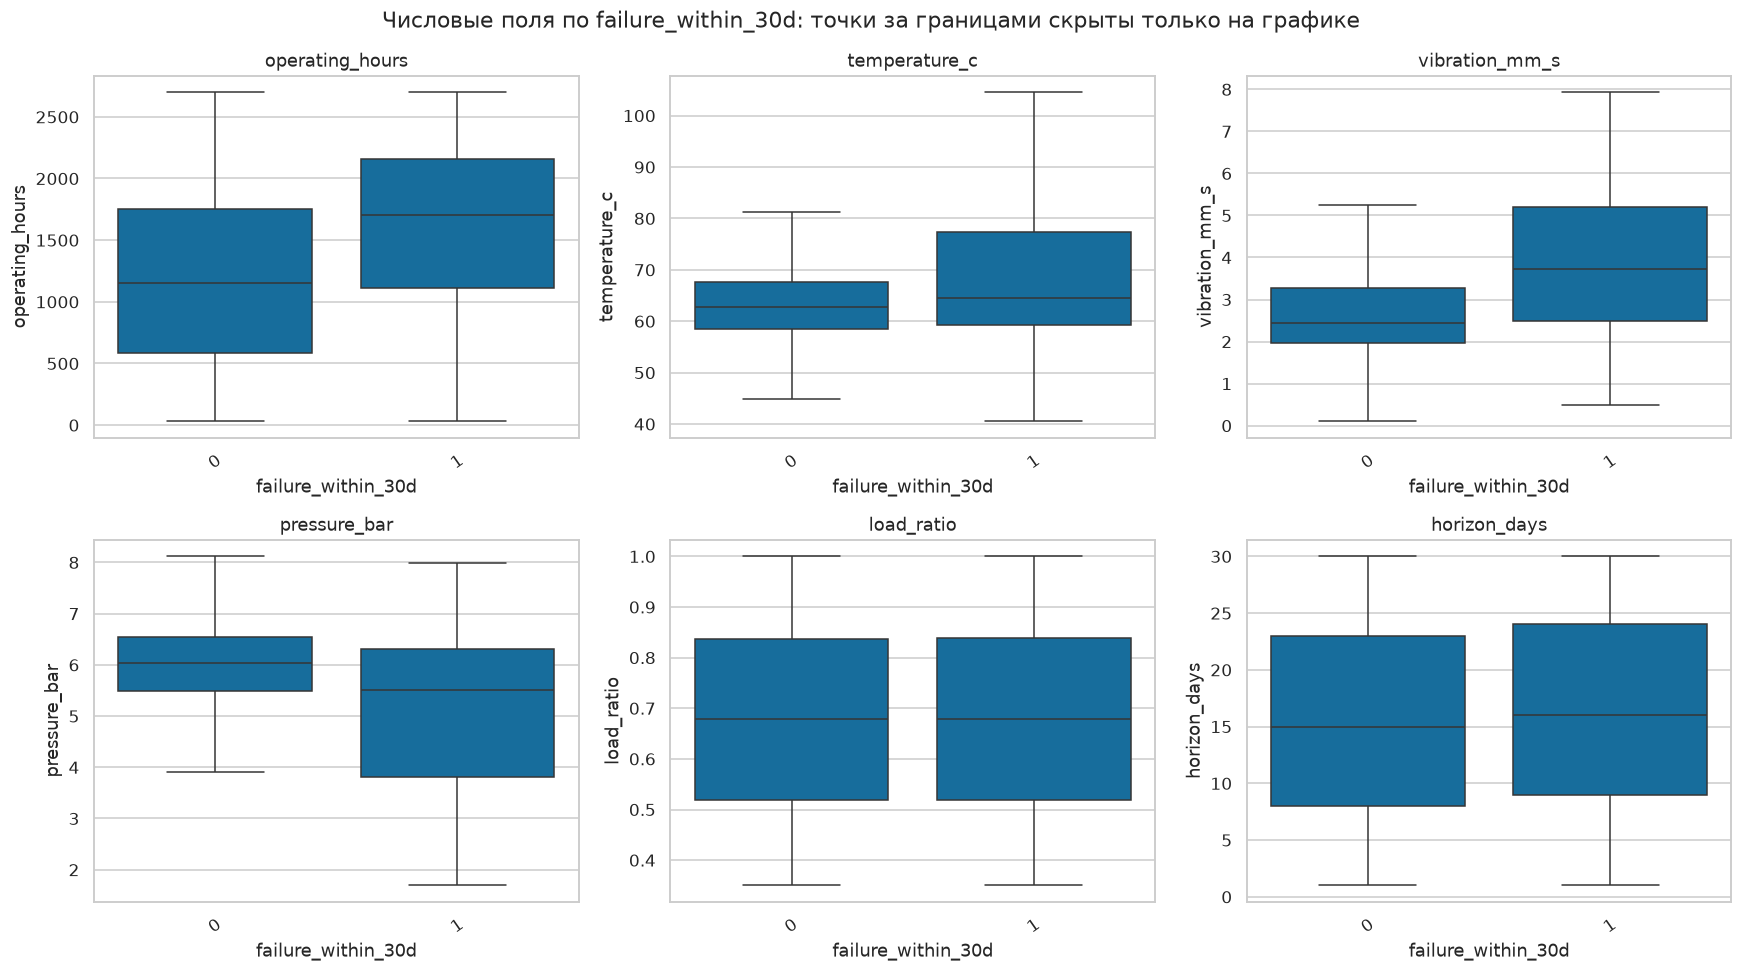

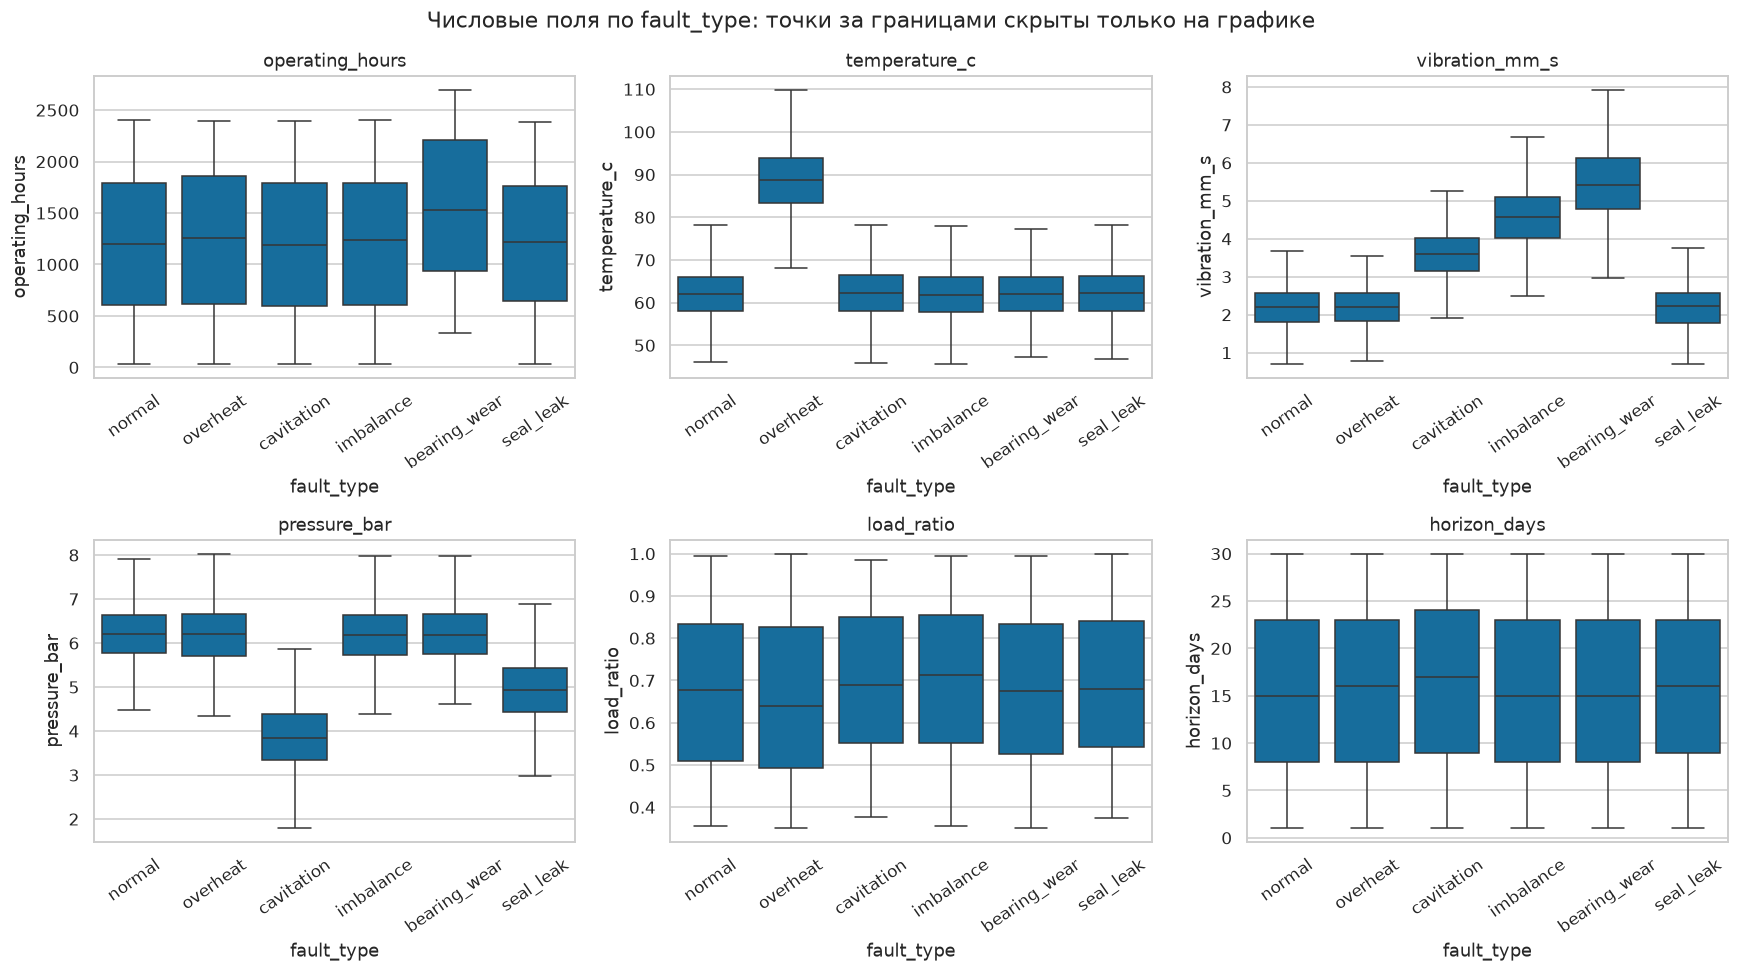

In [8]:
tables["train_numeric_summary"] = eda.numeric_summary(train, numeric)
display(tables["train_numeric_summary"])
figure = plots.numerical_distributions(train, numeric)
figure.savefig(figure_directory / "numeric_distributions.png")
plt.show()
plt.close(figure)

for target in targets:
    figure = plots.numeric_by_target(train, numeric, target)
    figure.savefig(figure_directory / f"numeric_by_{target}.png")
    plt.show()
    plt.close(figure)

## 7. IQR: крайние значения, стороны и частоты отказов

Источники: Т1/Т2, ячейки 6–10; основной EDA, раздел 5.
IQR — разность 75-го и 25-го процентилей. Границы вычисляются
**только на train**: `Q1 − k × IQR`, `Q3 + k × IQR`.
Группы сравниваются по числу наблюдений и наблюдаемой доле отказов.
Ничего не удаляем; связь не доказывает причинность или ошибку датчика.
Числа отличаются от анализа полного CSV в командных тетрадях.

In [9]:
quartiles = train[numeric].quantile([0.25, 0.75]).T
bounds = quartiles.rename(columns={0.25: "q1", 0.75: "q3"})
bounds["iqr"] = bounds["q3"] - bounds["q1"]
bounds["lower"] = bounds["q1"] - CONFIG["iqr_multiplier"] * bounds["iqr"]
bounds["upper"] = bounds["q3"] + CONFIG["iqr_multiplier"] * bounds["iqr"]
outlier_masks = {}
outlier_records = []
for field in numeric:
    lower_mask = train[field].lt(bounds.loc[field, "lower"])
    upper_mask = train[field].gt(bounds.loc[field, "upper"])
    outlier_masks[field] = lower_mask | upper_mask
    outlier_records.append(
        {
            "field": field,
            "below": int(lower_mask.sum()),
            "above": int(upper_mask.sum()),
            "outside": int(outlier_masks[field].sum()),
            "share": float(outlier_masks[field].mean()),
        }
    )
tables["train_iqr_bounds"] = bounds
tables["train_outlier_counts"] = pd.DataFrame(outlier_records)
display(bounds)
display(tables["train_outlier_counts"])

,q1,q3,iqr,lower,upper
operating_hours,643.5000,1836.000,1192.5000,-1145.25000,3624.75000
temperature_c,58.5500,68.150,9.6000,44.15000,82.55000
vibration_mm_s,2.0070,3.737,1.7300,-0.58800,6.33200
pressure_bar,5.3455,6.510,1.1645,3.59875,8.25675
load_ratio,0.5190,0.837,0.3180,0.04200,1.31400
horizon_days,8.0000,23.000,15.0000,-14.50000,45.50000


,field,below,above,outside,share
0,operating_hours,0,0,0,0.000000
1,temperature_c,16,942,958,0.089911
2,vibration_mm_s,0,218,218,0.020460
3,pressure_bar,435,4,439,0.041201
4,load_ratio,0,0,0,0.000000
5,horizon_days,0,0,0,0.000000


In [10]:
outlier_rates = []
outlier_breakdowns = []
for field, outside in outlier_masks.items():
    for label, mask in [("outside", outside), ("inside", ~outside)]:
        part = train.loc[mask]
        outlier_rates.append(
            {
                "field": field,
                "group": label,
                "records": len(part),
                "failures": int(part["failure_within_30d"].sum()),
                "failure_rate": part["failure_within_30d"].mean(),
            }
        )
    diagnostic = train.assign(outside=outside)
    for grouping in ["fault_type", "equipment"]:
        breakdown = (
            diagnostic.groupby(grouping)
            .agg(
                records=("id", "size"),
                outside=("outside", "sum"),
                failure_rate=("failure_within_30d", "mean"),
            )
            .reset_index()
        )
        breakdown["outside_share"] = (
            breakdown["outside"] / breakdown["records"]
        )
        breakdown = breakdown.rename(columns={grouping: "value"})
        breakdown["field"] = field
        breakdown["grouping"] = grouping
        outlier_breakdowns.append(breakdown)
tables["train_outlier_failure_rates"] = pd.DataFrame(outlier_rates)
tables["train_outlier_breakdowns"] = pd.concat(
    outlier_breakdowns, ignore_index=True
)
display(tables["train_outlier_failure_rates"])
display(tables["train_outlier_breakdowns"].query("outside > 0"))

,field,group,records,failures,failure_rate
0,operating_hours,outside,0,0,NaN
1,operating_hours,inside,10655,1785,0.167527
2,temperature_c,outside,958,427,0.445720
3,temperature_c,inside,9697,1358,0.140043
4,vibration_mm_s,outside,218,144,0.660550
5,vibration_mm_s,inside,10437,1641,0.157229
6,pressure_bar,outside,439,358,0.815490
7,pressure_bar,inside,10216,1427,0.139683
8,load_ratio,outside,0,0,NaN
9,load_ratio,inside,10655,1785,0.167527


,value,records,outside,failure_rate,outside_share,field,grouping
12,bearing_wear,1261,2,0.378271,0.001586,temperature_c,fault_type
13,cavitation,1069,1,0.513564,0.000935,temperature_c,fault_type
14,imbalance,1147,7,0.148213,0.006103,temperature_c,fault_type
15,normal,4783,8,0.000000,0.001673,temperature_c,fault_type
16,overheat,1215,938,0.361317,0.772016,temperature_c,fault_type
17,seal_leak,1180,2,0.127119,0.001695,temperature_c,fault_type
18,CM-110,1802,158,0.172031,0.087680,temperature_c,equipment
19,CP-500,1727,155,0.158657,0.089751,temperature_c,equipment
20,FV-40,1788,169,0.170022,0.094519,temperature_c,equipment
21,PN-200,1826,162,0.173604,0.088719,temperature_c,equipment


In [11]:
outlier_sides = []
for field in numeric:
    for side, mask in [
        ("below", train[field].lt(bounds.loc[field, "lower"])),
        ("above", train[field].gt(bounds.loc[field, "upper"])),
    ]:
        side_counts = (
            train.loc[mask]
            .groupby("fault_type")
            .agg(
                records=("id", "size"),
                failure_rate=("failure_within_30d", "mean"),
            )
            .reset_index()
        )
        side_counts["field"] = field
        side_counts["side"] = side
        outlier_sides.append(side_counts)
tables["train_outlier_sides"] = pd.concat(outlier_sides, ignore_index=True)
display(tables["train_outlier_sides"])

,fault_type,records,failure_rate,field,side
0,bearing_wear,1,1.000000,temperature_c,below
1,cavitation,1,0.000000,temperature_c,below
2,imbalance,6,0.166667,temperature_c,below
3,normal,7,0.000000,temperature_c,below
4,seal_leak,1,1.000000,temperature_c,below
5,bearing_wear,1,1.000000,temperature_c,above
6,imbalance,1,1.000000,temperature_c,above
7,normal,1,0.000000,temperature_c,above
8,overheat,938,0.449893,temperature_c,above
9,seal_leak,1,0.000000,temperature_c,above


## 8. Числовые связи и описательные сравнения с целями

Источники: основной EDA, разделы 6 и 8. Spearman correlation
показывает монотонную связь рангов, но не причинность. Для числовых
полей используются Mann–Whitney U / rank-biserial при двух классах
и Kruskal–Wallis / epsilon-squared при нескольких. Для категорий —
Chi-square / corrected Cramér's V с отметкой разреженных таблиц.

p-value и q-value (BH) описывают статистические сравнения;
независимость записей не установлена. Повторяющиеся журналы и
большой размер выборки ограничивают их интерпретацию. Разные меры
эффекта напрямую не сопоставляются. Автоматического отбора по ним нет.
Английские названия сохранены до согласования терминов в глоссарии.

,operating_hours,temperature_c,vibration_mm_s,pressure_bar,load_ratio,horizon_days,operator_log_length
operating_hours,1.000000,-0.019912,0.083557,0.015489,-0.009204,-0.023543,0.054843
temperature_c,-0.019912,1.000000,-0.104421,0.060467,-0.017456,0.001255,0.323953
vibration_mm_s,0.083557,-0.104421,1.000000,-0.058467,0.037460,-0.017958,0.352626
pressure_bar,0.015489,0.060467,-0.058467,1.000000,-0.032397,-0.024813,-0.284388
load_ratio,-0.009204,-0.017456,0.037460,-0.032397,1.000000,0.004381,0.009590
horizon_days,-0.023543,0.001255,-0.017958,-0.024813,0.004381,1.000000,0.011832
operator_log_length,0.054843,0.323953,0.352626,-0.284388,0.009590,0.011832,1.000000


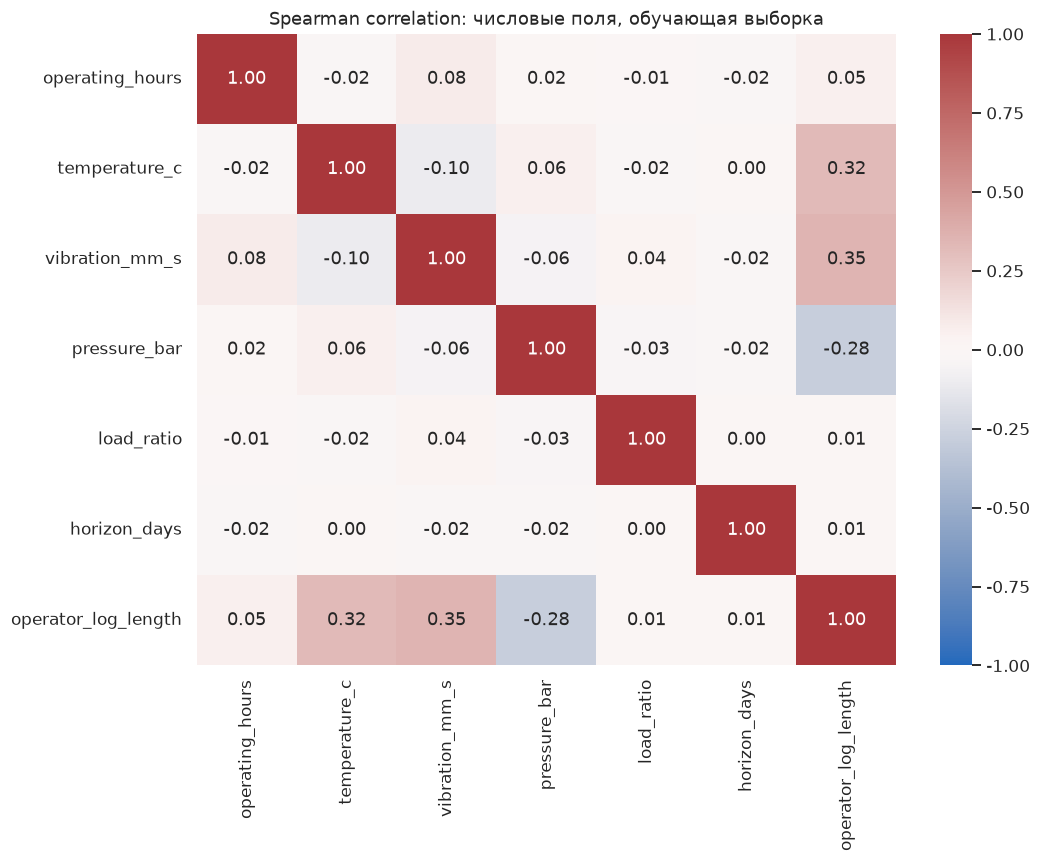

,Поле,Цель,Метод,Эффект,p-value,n,Примечание,q-value (BH)
6,operator_log_length,failure_within_30d,Mann–Whitney U / rank-biserial,0.678525,0.000000e+00,10655,Описательное сравнение; независимость событий не подтверждена.,0.000000e+00
10,required_route,failure_within_30d,Chi-square / corrected Cramér's V,0.495996,0.000000e+00,10655,Описательное сравнение; ассоциация не доказывает допустимость входа.,0.000000e+00
9,severity,failure_within_30d,Chi-square / corrected Cramér's V,0.749036,0.000000e+00,10655,Описательное сравнение; ассоциация не доказывает допустимость входа.,0.000000e+00
2,vibration_mm_s,failure_within_30d,Mann–Whitney U / rank-biserial,0.408094,1.847334e-163,10655,Описательное сравнение; независимость событий не подтверждена.,5.080168e-163
0,operating_hours,failure_within_30d,Mann–Whitney U / rank-biserial,0.341965,2.253522e-115,10655,Описательное сравнение; независимость событий не подтверждена.,4.957748e-115
3,pressure_bar,failure_within_30d,Mann–Whitney U / rank-biserial,-0.307576,1.045826e-93,10655,Описательное сравнение; независимость событий не подтверждена.,1.917347e-93
1,temperature_c,failure_within_30d,Mann–Whitney U / rank-biserial,0.160090,1.154551e-26,10655,Описательное сравнение; независимость событий не подтверждена.,1.814294e-26
5,horizon_days,failure_within_30d,Mann–Whitney U / rank-biserial,0.043086,3.999392e-03,10655,Описательное сравнение; независимость событий не подтверждена.,5.499164e-03
8,manual_id,failure_within_30d,Chi-square / corrected Cramér's V,0.000000,5.031475e-01,10655,Описательное сравнение; ассоциация не доказывает допустимость входа.,6.149581e-01
7,equipment,failure_within_30d,Chi-square / corrected Cramér's V,0.000000,8.570336e-01,10655,Описательное сравнение; ассоциация не доказывает допустимость входа.,8.570336e-01


In [12]:
text_lengths = train["operator_log"].fillna("").str.len()
numeric_diagnostic = train.assign(operator_log_length=text_lengths)
correlation_fields = numeric + ["operator_log_length"]
tables["train_spearman"] = numeric_diagnostic[correlation_fields].corr(
    method="spearman"
)
display(tables["train_spearman"])
figure = plots.correlation_plot(numeric_diagnostic, correlation_fields)
figure.savefig(figure_directory / "numeric_correlations.png")
plt.show()
plt.close(figure)

associations = eda.association_table(train, CONFIG)
tables["train_associations"] = associations
display(associations)

## 9. Категории и manual_id: исследовать до решения

Источники: основной EDA, раздел 7; Т1/Т2, ячейки 3–4.
Добавлены частоты всех категорий, явные проверки соответствий
`equipment`/`manual_id` и связей с целями на train. На графике
`manual_id` показаны только наиболее частые категории; полные
таблицы сохраняются. Идентификатор руководства не доказывает
наличие документа и сам по себе не доказывает бесполезность поля.

### equipment: категории train

,Число,Доля
equipment,,
PN-200,1826,0.171375
CM-110,1802,0.169122
FV-40,1788,0.167809
PN-300,1767,0.165838
TR-90,1745,0.163773
CP-500,1727,0.162084


### manual_id: категории train

,Число,Доля
manual_id,,
MAN-PN-12,222,0.020835
MAN-PN-07,219,0.020554
MAN-PN-18,217,0.020366
MAN-PN-13,216,0.020272
MAN-PN-17,213,0.019991
...,...,...
MAN-CP-10,82,0.007696
MAN-CM-06,81,0.007602
MAN-FV-10,80,0.007508


### severity: категории train

,Число,Доля
severity,,
low,7408,0.695260
medium,2639,0.247677
high,608,0.057062


### required_route: категории train

,Число,Доля
required_route,,
no_action,4783,0.448897
bearing_diagnostics,1261,0.118348
thermal_inspection,1215,0.114031
seal_repair,1180,0.110746
balancing,1147,0.107649
hydraulic_inspection,1069,0.100328


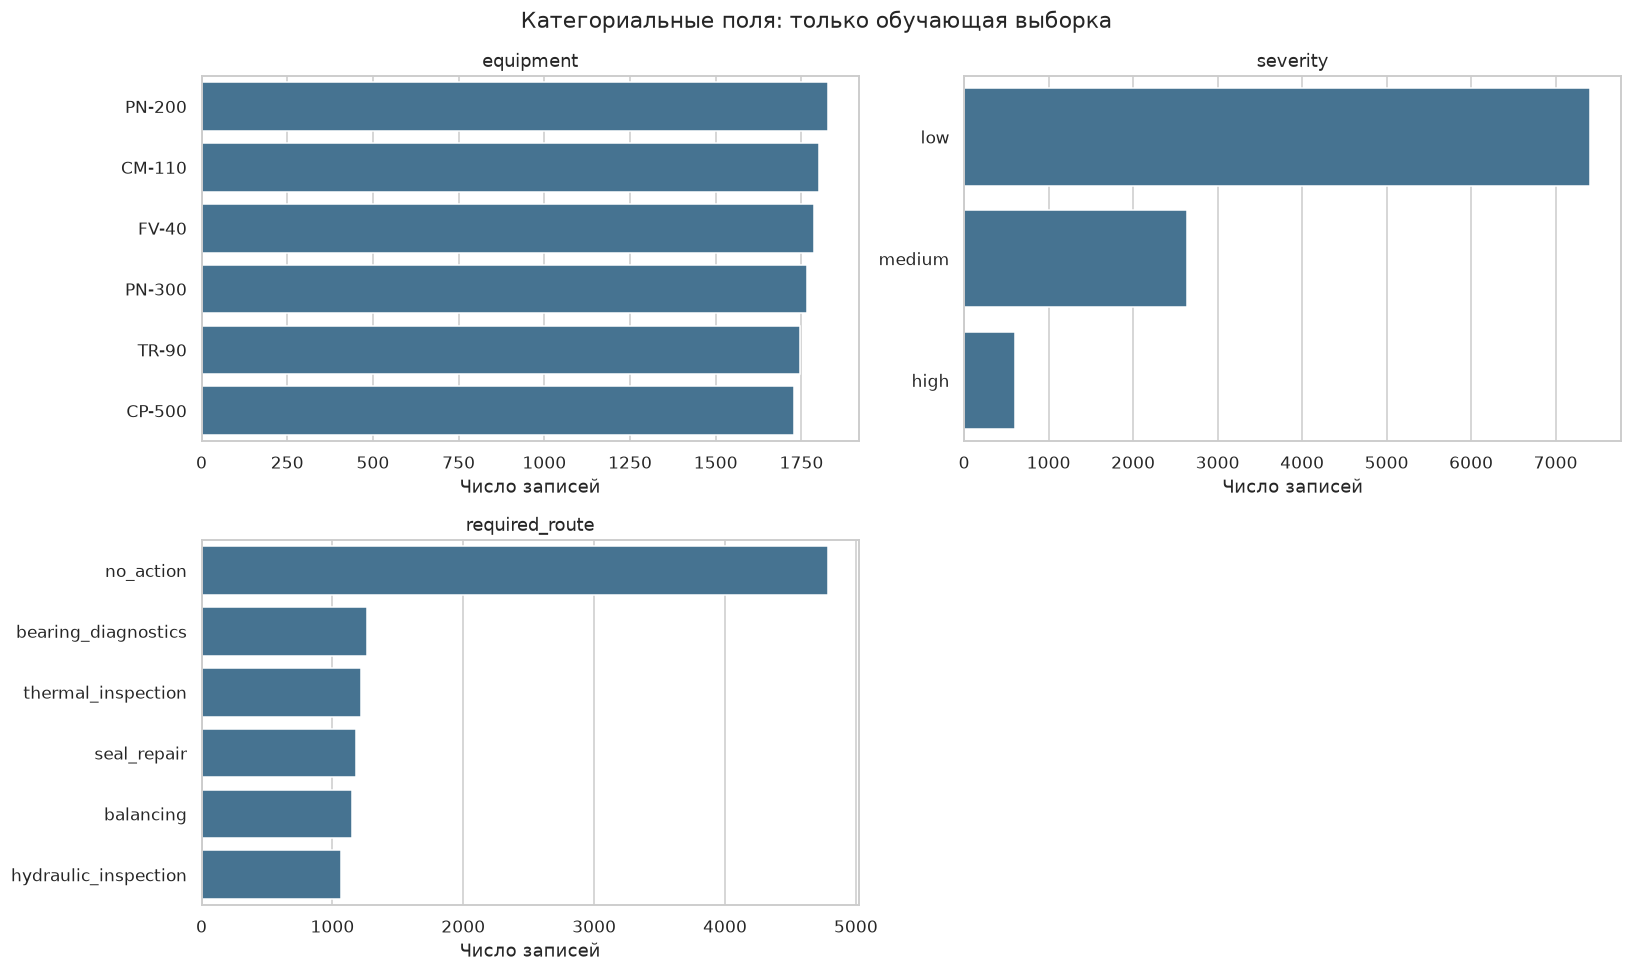

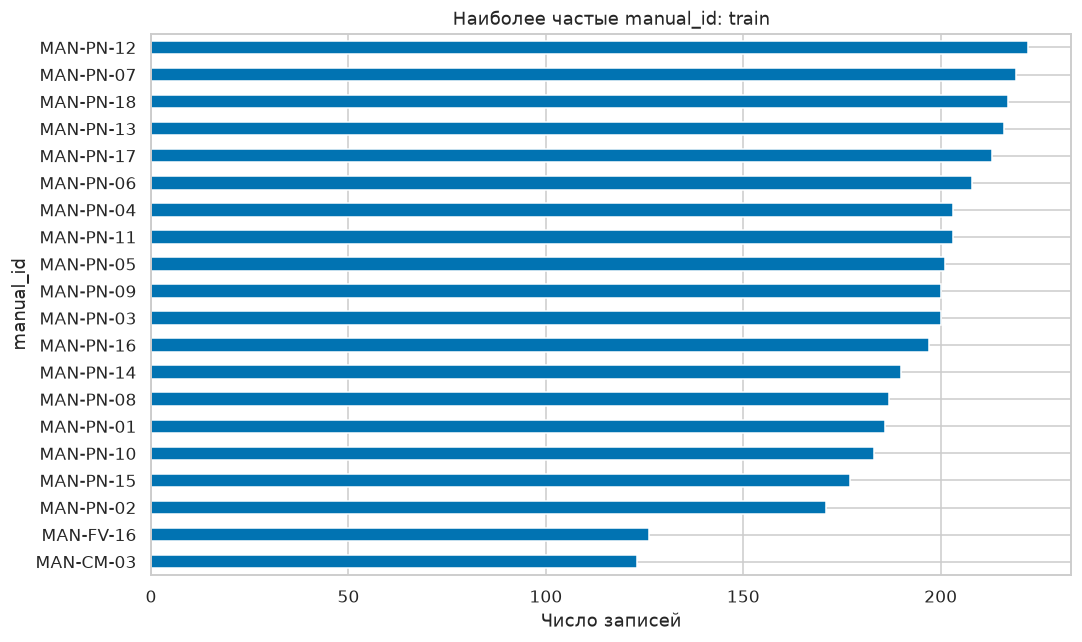

In [13]:
for field in categorical:
    tables[f"train_categories_{field}"] = eda.class_balance(train, field)
    display(Markdown(f"### {field}: категории train"))
    display(tables[f"train_categories_{field}"])

figure = plots.categorical_panels(
    train, ["equipment", "severity", "required_route"]
)
figure.savefig(figure_directory / "categorical_distributions.png")
plt.show()
plt.close(figure)

manual_counts = (
    train["manual_id"].value_counts().head(CONFIG["top_categories_plot"])
)
figure, axis = plt.subplots(figsize=(10, 6))
manual_counts.sort_values().plot.barh(ax=axis)
axis.set_title("Наиболее частые manual_id: train")
axis.set_xlabel("Число записей")
axis.set_ylabel("manual_id")
figure.tight_layout()
figure.savefig(figure_directory / "manual_id_top_counts.png")
plt.show()
plt.close(figure)

In [14]:
relationship_pairs = [
    ("equipment", "manual_id"),
    ("fault_type", "required_route"),
    ("fault_type", "severity"),
    ("fault_type", "failure_within_30d"),
    ("severity", "failure_within_30d"),
    ("manual_id", "fault_type"),
    ("manual_id", "failure_within_30d"),
]
relationship_summaries = []
for left, right in relationship_pairs:
    relationship = eda.field_relationships(train, left, right)
    table_name = f"train_relationship_{left}__{right}"
    tables[table_name] = relationship["table"]
    relationship_summaries.append(relationship["summary"])
    display(Markdown(f"### {left} × {right}: train"))
    if left == "manual_id":
        display(relationship["table"].head(CONFIG["top_categories_plot"]))
    else:
        display(relationship["table"])
    display(relationship["summary"])
tables["train_relationship_summary"] = pd.DataFrame(relationship_summaries)

### equipment × manual_id: train

manual_id,MAN-CM-01,MAN-CM-02,MAN-CM-03,MAN-CM-04,MAN-CM-05,MAN-CM-06,MAN-CM-07,MAN-CM-08,MAN-CM-09,MAN-CM-10,...,MAN-TR-09,MAN-TR-10,MAN-TR-11,MAN-TR-12,MAN-TR-13,MAN-TR-14,MAN-TR-15,MAN-TR-16,MAN-TR-17,MAN-TR-18
equipment,,,,,,,,,,,,,,,,,,,,,
CM-110,86,106,123,96,109,81,86,90,100,97,...,0,0,0,0,0,0,0,0,0,0
CP-500,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
FV-40,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
PN-200,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
PN-300,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
TR-90,0,0,0,0,0,0,0,0,0,0,...,93,87,94,112,103,121,96,117,94,79


{'Поле слева': 'equipment',
 'Поле справа': 'manual_id',
 'Каждое левое значение связано ровно с одним правым': False,
 'Каждое правое значение связано ровно с одним левым': False,
 'Это причинная или временная связь': 'Не установлено по таблице частот.'}

### fault_type × required_route: train

required_route,balancing,bearing_diagnostics,hydraulic_inspection,no_action,seal_repair,thermal_inspection
fault_type,,,,,,
bearing_wear,0,1261,0,0,0,0
cavitation,0,0,1069,0,0,0
imbalance,1147,0,0,0,0,0
normal,0,0,0,4783,0,0
overheat,0,0,0,0,0,1215
seal_leak,0,0,0,0,1180,0


...

fault_type,bearing_wear,cavitation,imbalance,normal,overheat,seal_leak
manual_id,,,,,,
MAN-CM-01,12,8,12,37,10,7
MAN-CM-02,13,7,8,57,7,14
MAN-CM-03,19,7,8,57,15,17
MAN-CM-04,14,11,11,40,8,12
MAN-CM-05,19,12,8,51,7,12
MAN-CM-06,10,7,13,31,10,10
MAN-CM-07,9,9,9,35,16,8
MAN-CM-08,13,11,14,35,9,8
MAN-CM-09,14,6,14,39,9,18


{'Поле слева': 'manual_id',
 'Поле справа': 'fault_type',
 'Каждое левое значение связано ровно с одним правым': False,
 'Каждое правое значение связано ровно с одним левым': False,
 'Это причинная или временная связь': 'Не установлено по таблице частот.'}

### manual_id × failure_within_30d: train

failure_within_30d,0,1
manual_id,,
MAN-CM-01,72,14
MAN-CM-02,92,14
MAN-CM-03,98,25
MAN-CM-04,79,17
MAN-CM-05,93,16
MAN-CM-06,68,13
MAN-CM-07,73,13
MAN-CM-08,72,18
MAN-CM-09,83,17


{'Поле слева': 'manual_id',
 'Поле справа': 'failure_within_30d',
 'Каждое левое значение связано ровно с одним правым': False,
 'Каждое правое значение связано ровно с одним левым': False,
 'Это причинная или временная связь': 'Не установлено по таблице частот.'}

## 10. Подгруппы equipment и severity

Источники: основной EDA, раздел 9; Т1/Т2, ячейка 15.
Для каждой группы показываем число записей и наблюдаемую долю
отказов на train. Сильная связь `severity` с целью не устанавливает
момент получения поля и не разрешает включение во входы.
`required_route` также остаётся полем с неизвестной доступностью.

,Число записей,Доля failure_within_30d = 1
equipment,,
CM-110,1802,0.172031
CP-500,1727,0.158657
FV-40,1788,0.170022
PN-200,1826,0.173604
PN-300,1767,0.165252
TR-90,1745,0.165043


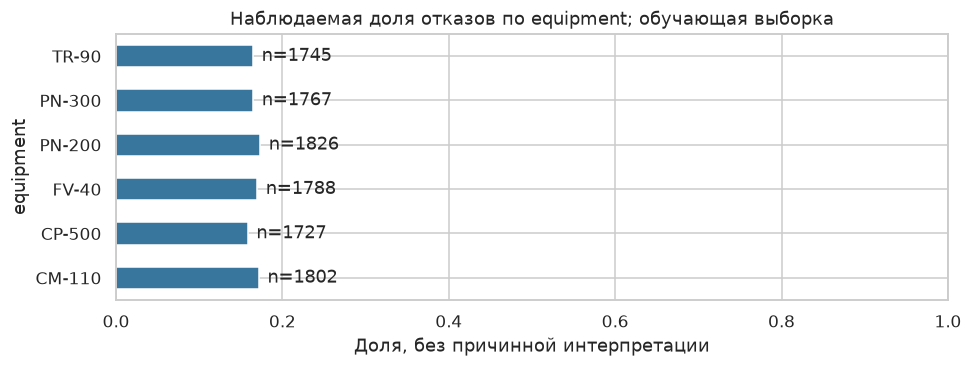

,Число записей,Доля failure_within_30d = 1
severity,,
high,608,1.000000
low,7408,0.000000
medium,2639,0.446002


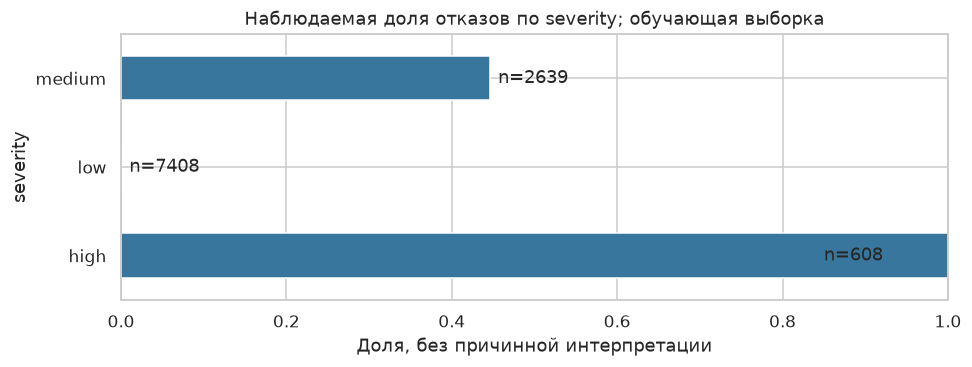

In [15]:
for field in ["equipment", "severity"]:
    figure, subgroup = plots.failure_by_category(train, field)
    tables[f"train_failure_by_{field}"] = subgroup
    display(subgroup)
    figure.savefig(figure_directory / f"failure_by_{field}.png")
    plt.show()
    plt.close(figure)

## 11. id: идентификатор, а не время или измерение

Источники: основной EDA, раздел 11; Т1/Т2, ячейка 15.
Проверяем диапазоны `id` по классам лишь как диагностический
признак возможного порядка формирования источника. Даже связь
с целью не превратила бы `id` в допустимый вход. Ни сортировка
по нему, ни порядок строк не задают историю отдельной машины.

In [16]:
numeric_ids = pd.to_numeric(train["id"], errors="raise")
id_diagnostic = train.assign(numeric_id=numeric_ids)
tables["train_id_by_fault"] = id_diagnostic.groupby("fault_type")[
    "numeric_id"
].agg(["min", "max", "mean", "count"])
display(tables["train_id_by_fault"])

,min,max,mean,count
fault_type,,,,
bearing_wear,16,14988,7610.87391,1261
cavitation,7,14996,7472.762395,1069
imbalance,15,15000,7612.992153,1147
normal,2,14991,7489.798871,4783
overheat,6,14994,7423.483951,1215
seal_leak,19,14960,7420.087288,1180


## 12. Текст: длины, примеры и совпадение нагрузки

Источники: основной EDA, раздел 10; Т1/Т2, ячейка 12.
Примеры берутся только с train. Для нагрузки используется формат
`нагрузка <число>%`, например `Нагрузка 65%` или `нагрузка 65,5%`.
Регулярное выражение допускает точку/запятую и пробелы; тексты,
не соответствующие формату, учитываются как неразобранные.
Сравнение с `load_ratio × 100` проводится в процентных пунктах.
Допуск из конфигурации — диагностическая настройка для проверки
округления, а не физический норматив или правило изменения данных.

In [17]:
text_summary, load_check = eda.text_audit(train)
tables["train_text_summary"] = text_summary
tables["train_log_load_check"] = load_check
load_difference = load_check["Разница, процентные пункты"]
parsed_loads = load_difference.notna()
load_mismatches = load_difference.abs().gt(
    CONFIG["load_tolerance_percentage_points"]
)
load_summary = pd.Series(
    {
        "Всего записей train": len(train),
        "Нагрузка разобрана": int(parsed_loads.sum()),
        "Нагрузка не разобрана": int((~parsed_loads).sum()),
        "Расхождений сверх допуска": int(load_mismatches.sum()),
        "Максимальное расхождение, п.п.": load_difference.abs().max(),
    }
)
tables["train_log_load_summary"] = load_summary.to_frame("Значение")
display(text_summary)
display(load_summary)
display(load_check.loc[load_mismatches].head(20))

example_logs = train.groupby("fault_type").head(CONFIG["examples_per_class"])[
    ["id", "fault_type", "operator_log"]
]
tables["train_example_logs"] = example_logs
display(example_logs)

,count,mean,std,min,25%,50%,75%,max
operator_log_length,10655.0,73.505209,6.367975,67.0,67.0,75.0,78.0,85.0
operator_log_words,10655.0,9.338620,1.339928,8.0,8.0,9.0,11.0,11.0


Всего записей train               10655.0
Нагрузка разобрана                10655.0
Нагрузка не разобрана                 0.0
Расхождений сверх допуска             0.0
Максимальное расхождение, п.п.        0.5
dtype: float64

,id,"Нагрузка в тексте, %",load_ratio × 100,"Разница, процентные пункты"


,id,fault_type,operator_log
1,2,normal,"Работа оборудования стабильна, посторонних шумов нет. Нагрузка 77%."
5,6,overheat,Зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. Нагрузка 41%.
6,7,cavitation,"Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка 71%."
8,9,cavitation,"Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка 89%."
9,10,normal,"Работа оборудования стабильна, посторонних шумов нет. Нагрузка 40%."
14,15,imbalance,После выхода на режим появилась повышенная вибрация и биение. Нагрузка 66%.
15,16,bearing_wear,Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка 70%.
17,18,overheat,Зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. Нагрузка 92%.
18,19,seal_leak,Обнаружены следы утечки в зоне уплотнения и снижение давления. Нагрузка 91%.
26,27,seal_leak,Обнаружены следы утечки в зоне уплотнения и снижение давления. Нагрузка 69%.


## 13. Точные журналы и шаблоны: что распознаёт текстовая модель

Источники: Т1/Т2, ячейки 11–13 и 17. В текущем варианте
соответствие журналов/шаблонов классам проверяется только на train.
Замена чисел на `<number>` нужна для диагностики повторения,
а не для создания утверждённого входа модели.

Маскирование не устраняет формулировку, связанную с диагнозом.
Высокое качество текста не доказывает качество на новых описаниях
или преимущество трансформера. Деление по шаблонам также не является
автоматическим исправлением: при одном шаблоне на класс удержание
шаблона одновременно убирает этот класс из обучающей выборки.

In [18]:
normalized_logs = train["operator_log"].map(data.normalize_log)
masked_logs = train["operator_log"].map(
    lambda value: data.normalize_log(value, mask_numbers=True)
)
text_diagnostic = train.assign(
    normalized_log=normalized_logs, masked_log=masked_logs
)
exact_mapping = text_diagnostic.groupby("normalized_log").agg(
    records=("id", "size"), fault_classes=("fault_type", "nunique")
)
template_mapping = text_diagnostic.groupby("masked_log").agg(
    records=("id", "size"), fault_classes=("fault_type", "nunique")
)
template_classes = pd.crosstab(
    text_diagnostic["masked_log"], text_diagnostic["fault_type"]
)
tables["train_exact_log_mapping"] = exact_mapping
tables["train_template_mapping"] = template_mapping
tables["train_template_classes"] = template_classes
display(exact_mapping.head(10))
display(template_mapping)
display(template_classes)

,records,fault_classes
normalized_log,,
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка 100%.,14,1
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка 35%.,12,1
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка 36%.,39,1
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка 37%.,31,1
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка 38%.,26,1
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка 40%.,21,1
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка 41%.,31,1
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка 42%.,19,1
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка 44%.,24,1


,records,fault_classes
masked_log,,
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка <number>%.,1215,1
обнаружены следы утечки в зоне уплотнения и снижение давления. нагрузка <number>%.,1180,1
оператор отмечает нарастающий гул в зоне подшипников и вибрацию. нагрузка <number>%.,1261,1
после выхода на режим появилась повышенная вибрация и биение. нагрузка <number>%.,1147,1
"работа оборудования стабильна, посторонних шумов нет. нагрузка <number>%.",4783,1
"слышен характерный шум, давление нестабильно, наблюдается вибрация. нагрузка <number>%.",1069,1


fault_type,bearing_wear,cavitation,imbalance,normal,overheat,seal_leak
masked_log,,,,,,
зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. нагрузка <number>%.,0,0,0,0,1215,0
обнаружены следы утечки в зоне уплотнения и снижение давления. нагрузка <number>%.,0,0,0,0,0,1180
оператор отмечает нарастающий гул в зоне подшипников и вибрацию. нагрузка <number>%.,1261,0,0,0,0,0
после выхода на режим появилась повышенная вибрация и биение. нагрузка <number>%.,0,0,1147,0,0,0
"работа оборудования стабильна, посторонних шумов нет. нагрузка <number>%.",0,0,0,4783,0,0
"слышен характерный шум, давление нестабильно, наблюдается вибрация. нагрузка <number>%.",0,1069,0,0,0,0


In [19]:
known_exact_logs = set(normalized_logs)
known_templates = set(masked_logs)
text_overlap_records = []
for partition in ["train", "validation", "test"]:
    texts = annotated.loc[annotated["split"].eq(partition), "operator_log"]
    exact = texts.map(data.normalize_log)
    masked = texts.map(
        lambda value: data.normalize_log(value, mask_numbers=True)
    )
    text_overlap_records.append(
        {
            "split": partition,
            "records": len(texts),
            "exact_logs": exact.nunique(),
            "templates": masked.nunique(),
            "seen_exact_share": exact.isin(known_exact_logs).mean(),
            "seen_template_share": masked.isin(known_templates).mean(),
        }
    )
tables["text_input_overlap"] = pd.DataFrame(text_overlap_records)
display(tables["text_input_overlap"])

,split,records,exact_logs,templates,seen_exact_share,seen_template_share
0,train,10655,281,6,1.0,1.0
1,validation,2193,59,6,0.0,1.0
2,test,2152,56,6,0.0,1.0


## 14. Частые слова по классам: описательные свидетельства

Источник: основной EDA, раздел 10. Словарь и частоты строятся
только по train. Считаются документы со словом, а не повторения
слова в одном документе; отношение долей имеет сглаживание.
Слова могут обозначать допустимые симптомы или готовую диагностику.
Без сведений о происхождении текста это остаётся открытым вопросом.

In [20]:
for target in targets:
    tokens = eda.token_associations(
        train,
        target,
        min_documents=CONFIG["min_token_documents"],
        top_n=CONFIG["top_tokens"],
    )
    tables[f"train_tokens_{target}"] = tokens
    display(Markdown(f"### Слова и {target}: train"))
    display(tokens)

### Слова и failure_within_30d: train

,Класс,Слово,Документов класса со словом,Доля в классе,Доля вне класса,Отношение долей со сглаживанием
0,0,нет,4783,0.539233,0.000000,963.594229
1,0,работа,4783,0.539233,0.000000,963.594229
2,0,посторонних,4783,0.539233,0.000000,963.594229
3,0,оборудования,4783,0.539233,0.000000,963.594229
4,0,шумов,4783,0.539233,0.000000,963.594229
5,0,стабильна,4783,0.539233,0.000000,963.594229
6,0,обнаружены,1030,0.116122,0.084034,1.375260
7,0,давления,1030,0.116122,0.084034,1.375260
8,0,снижение,1030,0.116122,0.084034,1.375260
9,0,уплотнения,1030,0.116122,0.084034,1.375260


### Слова и fault_type: train

,Класс,Слово,Документов класса со словом,Доля в классе,Доля вне класса,Отношение долей со сглаживанием
0,bearing_wear,вибрацию,1261,1.0,0.000000,9388.560570
1,bearing_wear,гул,1261,1.0,0.000000,9388.560570
2,bearing_wear,нарастающий,1261,1.0,0.000000,9388.560570
3,bearing_wear,отмечает,1261,1.0,0.000000,9388.560570
4,bearing_wear,оператор,1261,1.0,0.000000,9388.560570
5,bearing_wear,подшипников,1261,1.0,0.000000,9388.560570
6,bearing_wear,зоне,1261,1.0,0.125612,7.949670
7,bearing_wear,нагрузка,1261,1.0,1.000000,0.999315
8,bearing_wear,слышен,0,0.0,0.113796,0.006953
9,bearing_wear,наблюдается,0,0.0,0.113796,0.006953


## 15. Входные распределения train и validation

Дополнение к обеим работам. Сравниваем размеры, пропуски, квантили,
числовые распределения и доли категорий. Границы числовых интервалов
задаются квантилями **только train** и применяются к обеим частям.
Крайние интервалы открыты до бесконечности, чтобы не потерять
валидационные значения вне диапазона train. Для категорий отмечаем
значения, отсутствующие в train. Тестовые входные распределения
и целевые связи в этот этап не включаются.

Отличия могут объясняться групповым разбиением. Они описывают
ограничения, но не являются поводом перебирать seed ради сходства
частей. Нормализация текста здесь диагностическая; обучаемая
предобработка не выполняется.

In [21]:
development = {
    "train": train.assign(operator_log_length=text_lengths),
    "validation": validation.assign(
        operator_log_length=validation["operator_log"].fillna("").str.len()
    ),
}
comparison_fields = numeric + ["operator_log_length"]
development_records = []
interval_records = []
for field in comparison_fields:
    train_quantiles = (
        development["train"][field]
        .quantile(CONFIG["comparison_quantiles"])
        .dropna()
        .unique()
    )
    edges = [-np.inf, *sorted(train_quantiles), np.inf]
    for partition, sample in development.items():
        values = sample[field].replace([np.inf, -np.inf], np.nan)
        description = values.describe(
            percentiles=CONFIG["comparison_quantiles"]
        ).to_dict()
        description.update(
            {
                "field": field,
                "split": partition,
                "missing": int(values.isna().sum()),
            }
        )
        development_records.append(description)
        interval_counts = pd.cut(values, bins=edges).value_counts(sort=False)
        for interval, count in interval_counts.items():
            interval_records.append(
                {
                    "field": field,
                    "split": partition,
                    "interval": str(interval),
                    "records": int(count),
                    "share": count / values.notna().sum(),
                }
            )
tables["development_numeric_summary"] = pd.DataFrame(development_records)
tables["development_train_bins"] = pd.DataFrame(interval_records)
display(tables["development_numeric_summary"])
display(tables["development_train_bins"].head(20))

,count,mean,std,min,10%,25%,50%,75%,90%,max,field,split,missing
0,10655.0,1247.870389,693.332182,30.000,299.0000,643.5000,1246.000,1836.000,2202.0000,2699.000,operating_hours,train,0
1,2193.0,1255.309622,701.050481,31.000,292.0000,649.0000,1265.000,1857.000,2227.8000,2697.000,operating_hours,validation,0
2,10655.0,65.060629,10.469074,39.720,54.8500,58.5500,62.980,68.150,79.6280,118.760,temperature_c,train,0
3,2193.0,65.127246,10.555722,40.960,54.6900,58.5500,63.050,68.420,80.4900,108.660,temperature_c,validation,0
4,10655.0,2.975998,1.358167,0.101,1.6204,2.0070,2.537,3.737,5.1312,7.929,vibration_mm_s,train,0
5,2193.0,2.961594,1.359414,0.387,1.5994,1.9840,2.540,3.690,5.1002,7.912,vibration_mm_s,validation,0
6,10655.0,5.821375,1.020670,1.693,4.3534,5.3455,5.982,6.510,6.9396,8.593,pressure_bar,train,0
7,2193.0,5.816782,1.037486,1.572,4.2762,5.3150,6.004,6.533,6.9496,8.055,pressure_bar,validation,0
8,10655.0,0.675927,0.186439,0.350,0.4170,0.5190,0.679,0.837,0.9340,1.000,load_ratio,train,0
9,2193.0,0.706259,0.191207,0.350,0.4360,0.5350,0.758,0.861,0.9300,1.000,load_ratio,validation,0


,field,split,interval,records,share
0,operating_hours,train,"(-inf, 299.0]",1068,0.100235
1,operating_hours,train,"(299.0, 643.5]",1596,0.149789
2,operating_hours,train,"(643.5, 1246.0]",2666,0.250211
3,operating_hours,train,"(1246.0, 1836.0]",2662,0.249836
4,operating_hours,train,"(1836.0, 2202.0]",1600,0.150164
5,operating_hours,train,"(2202.0, inf]",1063,0.099765
6,operating_hours,validation,"(-inf, 299.0]",224,0.102143
7,operating_hours,validation,"(299.0, 643.5]",316,0.144095
8,operating_hours,validation,"(643.5, 1246.0]",548,0.249886
9,operating_hours,validation,"(1246.0, 1836.0]",534,0.243502


,value,train,validation,unseen_in_train,field
0,CM-110,0.169122,0.156863,False,equipment
1,CP-500,0.162084,0.145463,False,equipment
2,FV-40,0.167809,0.169631,False,equipment
3,PN-200,0.171375,0.167351,False,equipment
4,PN-300,0.165838,0.180119,False,equipment
5,TR-90,0.163773,0.180575,False,equipment
6,MAN-CM-01,0.008071,0.007752,False,manual_id
7,MAN-CM-02,0.009948,0.009120,False,manual_id
8,MAN-CM-03,0.011544,0.010944,False,manual_id
9,MAN-CM-04,0.009010,0.006384,False,manual_id


### Категории validation, отсутствующие в train

,value,train,validation,unseen_in_train,field


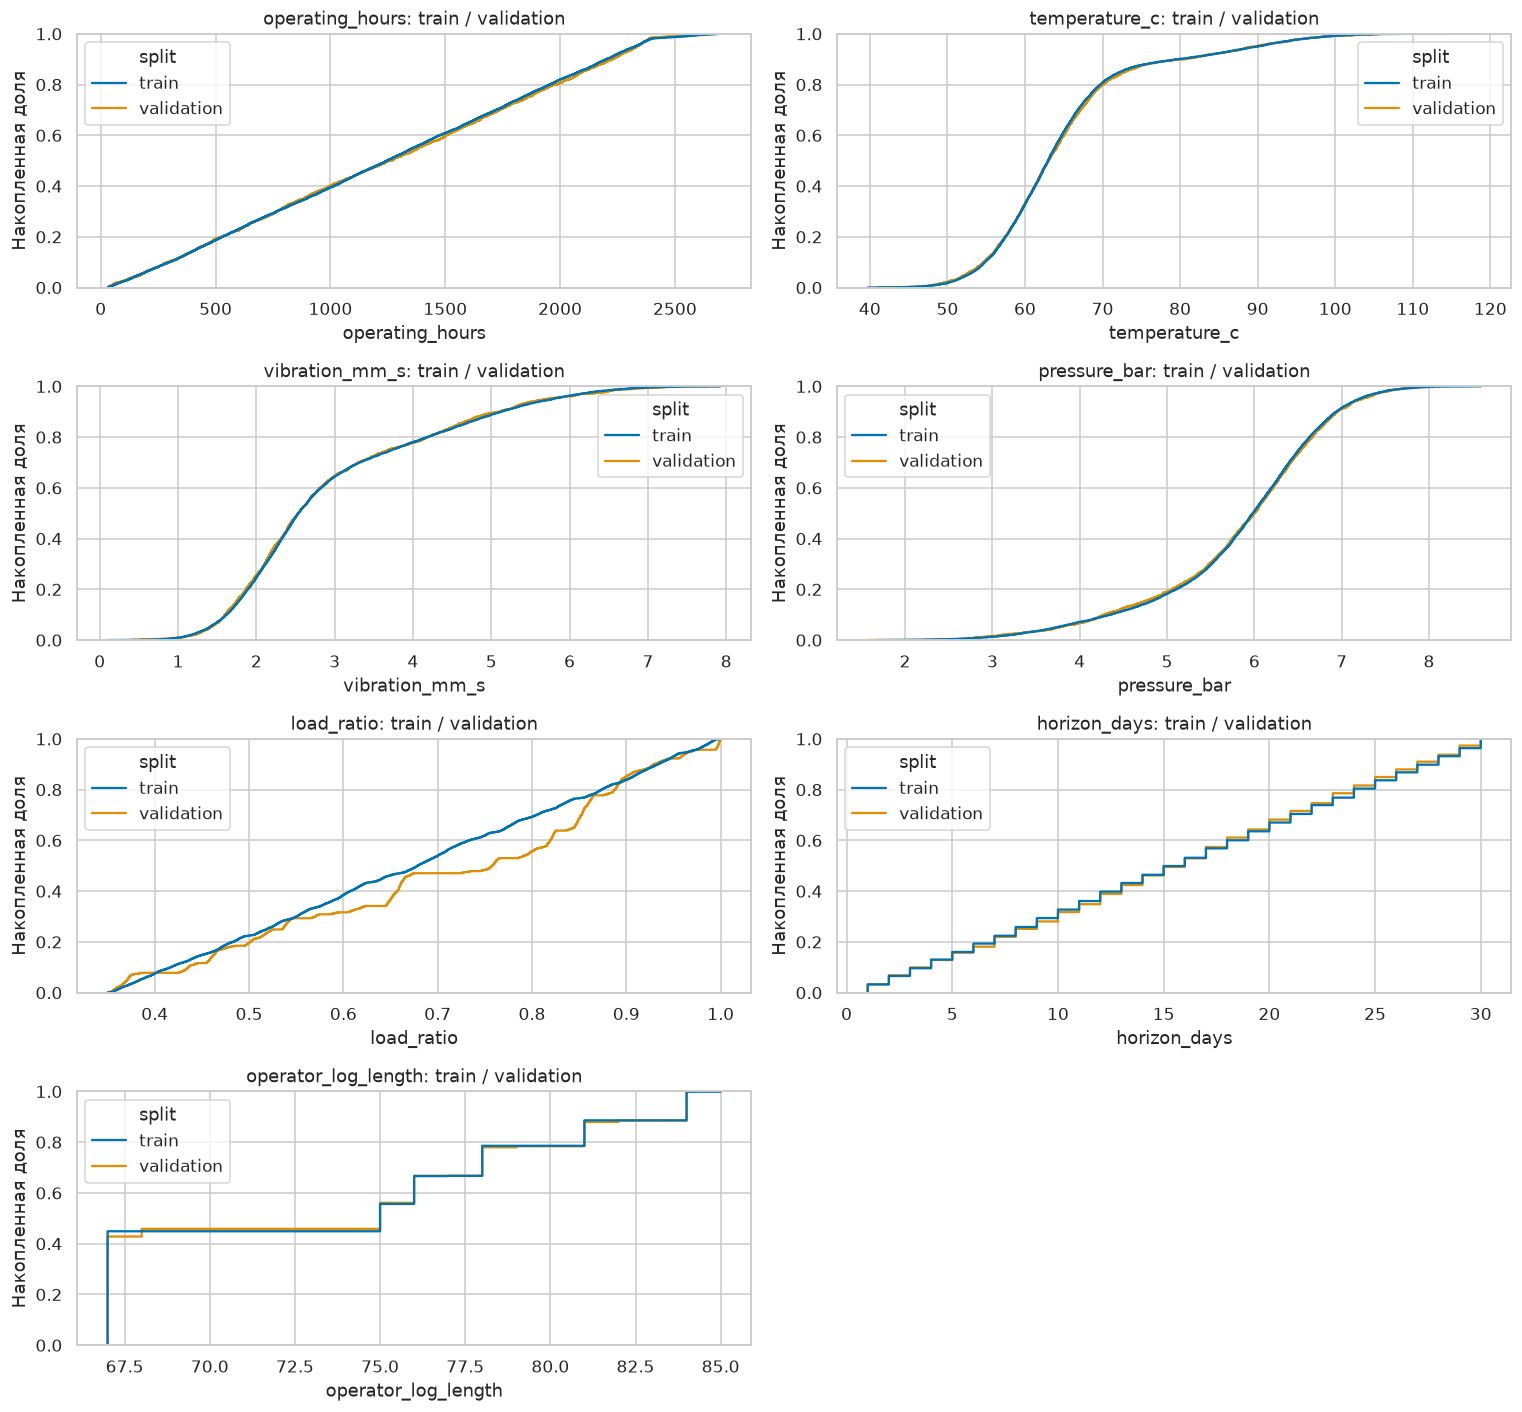

In [22]:
category_comparisons = []
for field in categorical:
    shares = {}
    for partition, sample in development.items():
        shares[partition] = (
            sample[field].fillna("<missing>").value_counts(normalize=True)
        )
    comparison = pd.DataFrame(shares).fillna(0)
    comparison["unseen_in_train"] = comparison["train"].eq(0)
    comparison["field"] = field
    comparison.index.name = "value"
    category_comparisons.append(comparison.reset_index())
tables["development_categories"] = pd.concat(
    category_comparisons, ignore_index=True
)
display(tables["development_categories"].head(20))
display(Markdown("### Категории validation, отсутствующие в train"))
display(tables["development_categories"].query("unseen_in_train"))

development_plot = pd.concat(
    [
        sample[comparison_fields].assign(split=partition)
        for partition, sample in development.items()
    ],
    ignore_index=True,
)
figure, axes = plt.subplots(4, 2, figsize=(14, 13))
for field, axis in zip(comparison_fields, axes.flat):
    sns.ecdfplot(data=development_plot, x=field, hue="split", ax=axis)
    axis.set_title(f"{field}: train / validation")
    axis.set_xlabel(field)
    axis.set_ylabel("Накопленная доля")
axes.flat[-1].set_visible(False)
figure.tight_layout()
figure.savefig(figure_directory / "development_distributions.png")
plt.show()
plt.close(figure)

## 16. Обоснование по каждому из 14 полей

Источники: основной EDA, раздел 12; Т1/Т2, ячейки 18 и 20–23.
Факты пересчитаны на train. Для `id` и целей роль уже определена;
для входов доступность пока неизвестна. Пять показаний — кандидаты
числового контроля A; `horizon_days` не добавляется к ним молча.
Пользу `equipment` и `manual_id` нельзя отвергать по типу столбца.

Итоговые решения и источник их обоснования заполняются командой
в отдельном `feature_decisions.csv`. При повторном запуске этот
файл сохраняется без перезаписи; свежие факты находятся в каталоге
текущего запуска. Сильная связь с целью не подтверждает допустимость
входа, а слабая связь не доказывает бесполезность.

In [23]:
ledger = eda.feature_ledger(train, associations, CONFIG)
numeric_evidence = (
    "train_numeric_summary.csv; train_outlier_counts.csv; "
    "train_associations.csv; development_numeric_summary.csv"
)
ledger["Файлы свидетельств"] = "source_quality.csv"
for field in numeric:
    ledger.loc[ledger["Поле"].eq(field), "Файлы свидетельств"] = (
        numeric_evidence
    )
for field in categorical:
    ledger.loc[ledger["Поле"].eq(field), "Файлы свидетельств"] = (
        f"train_categories_{field}.csv; train_associations.csv; "
        "train_relationship_summary.csv; development_categories.csv"
    )
ledger.loc[ledger["Поле"].eq("operator_log"), "Файлы свидетельств"] = (
    "train_text_summary.csv; train_template_classes.csv; "
    "train_log_load_check.csv; text_input_overlap.csv"
)
tables["feature_evidence"] = ledger
assert set(ledger["Поле"]) == set(data.EXPECTED_COLUMNS)
assert ledger["Поле"].is_unique
display(ledger)

decisions_path = output_root / "feature_decisions.csv"
if not decisions_path.exists():
    ledger.to_csv(decisions_path, index=False, encoding="utf-8-sig")
    logger.info("Создана таблица решений: %s", decisions_path)
else:
    logger.info("Существующая таблица решений сохранена без изменений")
decisions = pd.read_csv(decisions_path, keep_default_na=False)
assert decisions["Поле"].is_unique
assert set(decisions["Поле"]) == set(data.EXPECTED_COLUMNS)
tables["feature_decisions_snapshot"] = decisions
display(decisions[["Поле", "Решение команды", "Источник решения"]])

,Поле,Роль,Наблюдаемые факты,Доступность до прогноза,Статус,Обоснование / следующая проверка,Решение команды,Источник решения,Файлы свидетельств
0,id,Идентификатор записи,Различных значений: 10655; пропусков: 0.,не применимо,Не вход модели,Используется для связывания результатов; семантика времени/машины не подтверждена. Связь с целью...,,,source_quality.csv
1,equipment,Кандидат во входы,"Различных значений: 6; пропусков: 0. failure_within_30d: Chi-square / corrected Cramér's V, эффе...",unknown,Решение не принято,"Установить, обозначает тип или машину; сравнить числовой контроль A с дополнительным вариантом A...",,,train_categories_equipment.csv; train_associations.csv; train_relationship_summary.csv; developm...
2,operating_hours,Кандидат во входы,"Различных значений: 2494; пропусков: 0. failure_within_30d: Mann–Whitney U / rank-biserial, эффе...",unknown,Решение не принято,"Кандидат для числового базового решения A по заданию; ни корреляция, ни p-value по отдельности н...",,,train_numeric_summary.csv; train_outlier_counts.csv; train_associations.csv; development_numeric...
3,temperature_c,Кандидат во входы,"Различных значений: 3475; пропусков: 0. failure_within_30d: Mann–Whitney U / rank-biserial, эффе...",unknown,Решение не принято,"Кандидат для числового базового решения A по заданию; ни корреляция, ни p-value по отдельности н...",,,train_numeric_summary.csv; train_outlier_counts.csv; train_associations.csv; development_numeric...
4,vibration_mm_s,Кандидат во входы,"Различных значений: 4200; пропусков: 0. failure_within_30d: Mann–Whitney U / rank-biserial, эффе...",unknown,Решение не принято,"Кандидат для числового базового решения A по заданию; ни корреляция, ни p-value по отдельности н...",,,train_numeric_summary.csv; train_outlier_counts.csv; train_associations.csv; development_numeric...
5,pressure_bar,Кандидат во входы,"Различных значений: 3700; пропусков: 0. failure_within_30d: Mann–Whitney U / rank-biserial, эффе...",unknown,Решение не принято,"Кандидат для числового базового решения A по заданию; ни корреляция, ни p-value по отдельности н...",,,train_numeric_summary.csv; train_outlier_counts.csv; train_associations.csv; development_numeric...
6,load_ratio,Кандидат во входы,"Различных значений: 651; пропусков: 0. failure_within_30d: Mann–Whitney U / rank-biserial, эффек...",unknown,Решение не принято,"Кандидат для числового базового решения A по заданию; ни корреляция, ни p-value по отдельности н...",,,train_numeric_summary.csv; train_outlier_counts.csv; train_associations.csv; development_numeric...
7,operator_log,Кандидат во входы,"Различных значений: 281; пропусков: 0. failure_within_30d: Mann–Whitney U / rank-biserial, эффек...",unknown,Решение не принято,"Проанализирован как текст. Не входит в числовой контроль A по его определению, но сохраняется дл...",,,train_text_summary.csv; train_template_classes.csv; train_log_load_check.csv; text_input_overlap...
8,manual_id,Кандидат во входы,"Различных значений: 90; пропусков: 0. failure_within_30d: Chi-square / corrected Cramér's V, эфф...",unknown,Решение не принято,"Проверить связь с equipment и целями, доступность и дублирование информации; не исключать только...",,,train_categories_manual_id.csv; train_associations.csv; train_relationship_summary.csv; developm...
9,fault_type,Целевая переменная,Различных значений: 6; пропусков: 0.,не применимо,Не вход ни одной из двух моделей,Метки прогнозируются и используются отдельно для оценивания; их доступность до прогноза не устан...,,,source_quality.csv


2026-10-16 13:19:29,066 INFO Существующая таблица решений сохранена без изменений


,Поле,Решение команды,Источник решения
0,id,,
1,equipment,,
2,operating_hours,,
3,temperature_c,,
4,vibration_mm_s,,
5,pressure_bar,,
6,load_ratio,,
7,operator_log,,
8,manual_id,,
9,fault_type,,


## 17. Сохранение свидетельств и проверка целостности

В каждый новый каталог запуска записываются таблицы, графики,
конфигурация, журнал событий, контрольные суммы исходных тетрадей,
текущего кода и разбиения. Для объединённой тетради отдельно
вычисляется сумма исходных ячеек без результатов исполнения.
Сохранённое разбиение перечитывается для проверки стабильности.
Предыдущие результаты и пользовательские решения не заменяются.

In [24]:
reloaded_membership, _ = data.get_or_create_splits(PROJECT_ROOT, df, CONFIG)
pd.testing.assert_frame_equal(
    membership.astype("string"), reloaded_membership.astype("string")
)
assert data.file_sha256(PROJECT_ROOT / CONFIG["dataset"]) == (CONFIG["sha256"])
notebook_path = PROJECT_ROOT / CONFIG["notebook"]
notebook_document = json.loads(notebook_path.read_text(encoding="utf-8"))
source_cells = [
    {
        "cell_type": cell["cell_type"],
        "source": "".join(cell["source"]),
    }
    for cell in notebook_document["cells"]
]
source_payload = json.dumps(source_cells, ensure_ascii=False).encode("utf-8")
(run_directory / "notebook_source.json").write_bytes(source_payload)
source_checksums = {
    path: data.file_sha256(PROJECT_ROOT / path)
    for path in CONFIG["source_notebooks"]
}
module_checksums = {}
for module in [data, eda, plots]:
    module_path = Path(module.__file__)
    relative_path = str(module_path.relative_to(PROJECT_ROOT))
    module_checksums[relative_path] = data.file_sha256(module_path)
manifest.update(
    {
        "source": source_manifest,
        "split": split_manifest,
        "source_notebooks": source_checksums,
        "module_checksums": module_checksums,
        "notebook_source_sha256": hashlib.sha256(source_payload).hexdigest(),
        "config_sha256": data.file_sha256(CONFIG_PATH),
        "decision_file_sha256": data.file_sha256(decisions_path),
        "test_targets_used_for_feature_analysis": False,
        "prior_full_source_eda": True,
    }
)
for name, table in tables.items():
    table.to_csv(run_directory / f"{name}.csv", encoding="utf-8-sig")
manifest["table_count"] = len(tables)
manifest["figure_count"] = len(list(figure_directory.glob("*.png")))
manifest["duration_seconds"] = perf_counter() - started_clock
manifest["status"] = "tables_saved"
manifest_path.write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
logger.info(
    "Сохранены %s таблиц и %s графиков: %s",
    manifest["table_count"],
    manifest["figure_count"],
    run_directory,
)
display(
    pd.Series(
        {
            "Каталог результатов": str(
                run_directory.relative_to(PROJECT_ROOT)
            ),
            "Таблица решений": str(decisions_path.relative_to(PROJECT_ROOT)),
            "Разбиение": (
                f"Data/splits/{CONFIG['split_version']}/membership.csv"
            ),
        }
    )
)

2026-10-16 13:19:30,870 INFO Сохранены 49 таблиц и 10 графиков: C:\Users\Mo\work\study\Магистратура\2к\1с\LLMs\artifacts\eda\EDA-16-10\runs\20261016T100638_301364Z


Каталог результатов    artifacts\eda\EDA-16-10\runs\20261016T100638_301364Z
Таблица решений               artifacts\eda\EDA-16-10\feature_decisions.csv
Разбиение                                 Data/splits/eda_v1/membership.csv
dtype: str

## 18. Фактические наблюдения и готовность к базовому решению

Следующая ячейка формирует краткое описание из рассчитанных таблиц.
Решения о доступности полей и входах остаются открытыми; результат
не объявляется завершённым обучением или доказательством улучшения.

In [25]:
train_failure_share = train["failure_within_30d"].mean()
exact_overlap = tables["split_overlap"]["Общие точные тексты"].max()
masked_overlap = tables["split_overlap"]["Общие тексты без чисел"].max()
single_class_templates = template_mapping["fault_classes"].eq(1).sum()
outlier_total = int(tables["train_outlier_counts"]["outside"].sum())
open_decisions = decisions["Решение команды"].astype(str).str.strip().eq("")
manuals_by_equipment = train.groupby("manual_id")["equipment"].nunique()
shared_manuals = int(manuals_by_equipment.gt(1).sum())
routes_per_fault = train.groupby("fault_type")["required_route"].nunique()
faults_per_route = train.groupby("required_route")["fault_type"].nunique()
route_is_bijective = bool(
    routes_per_fault.eq(1).all() and faults_per_route.eq(1).all()
)
load_mean_difference = (
    validation["load_ratio"].mean() - train["load_ratio"].mean()
)
findings = f"""
### Результаты текущего запуска

- Проверен источник: {len(df):,} записей и {len(df.columns)} полей.
- Train: {len(train):,} записей; доля отказов {train_failure_share:.2%}.
- Общих точных журналов между частями: {exact_overlap}.
  Максимум общих шаблонов после маскирования чисел: {masked_overlap}.
- На train найдено {len(exact_mapping)} точных журналов и
  {len(template_mapping)} шаблонов; {single_class_templates} шаблонов
  встречаются только с одним классом неисправности.
- Отметок значений за границами IQR: {outlier_total}; одна запись
  может получить несколько отметок. Значения не удалялись.
- Расхождений нагрузки сверх диагностического допуска:
  {int(load_mismatches.sum())} из {int(parsed_loads.sum())} разобранных.
- Взаимно однозначное соответствие `fault_type`/`required_route`
  на train: {route_is_bijective}. Это наблюдение, а не причинная связь.
- Значений `manual_id`, связанных с несколькими `equipment` на train:
  {shared_manuals}. Два поля не следует объявлять взаимозаменяемыми
  без проверки; принадлежность к руководству не доказывает его наличие.
- Средняя `load_ratio` в validation отличается от train на
  {load_mean_difference:+.4f}. Это следствие состава частей;
  влияние на качество модели пока не проверялось.
- Полей без заполненного решения команды: {int(open_decisions.sum())}.

Для базового решения далее нужно подтвердить смысл и доступность
входов, заполнить решения по полям и зафиксировать протокол оценки.
`horizon_days`, `severity` и `required_route` не получают разрешения
на включение благодаря одной статистической связи. Эталонные цели
и `id` входами не являются. Текстовые сравнения требуют классической
текстовой модели и явной оговорки о повторяющихся формулировках.

Участники ранее исследовали весь источник. Текущие ограничения
выборок, отсутствие подтверждённой идентичности машин и временных
меток нужно сохранить в отчёте. Обучение моделей здесь не выполнено.
"""
display(Markdown(findings))
(run_directory / "findings.md").write_text(findings, encoding="utf-8")
manifest["duration_seconds"] = perf_counter() - started_clock
manifest["status"] = "completed"
manifest_path.write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
logger.info("EDA завершён; модели не обучались")


### Результаты текущего запуска

- Проверен источник: 15,000 записей и 14 полей.
- Train: 10,655 записей; доля отказов 16.75%.
- Общих точных журналов между частями: 0.
  Максимум общих шаблонов после маскирования чисел: 6.
- На train найдено 281 точных журналов и
  6 шаблонов; 6 шаблонов
  встречаются только с одним классом неисправности.
- Отметок значений за границами IQR: 1615; одна запись
  может получить несколько отметок. Значения не удалялись.
- Расхождений нагрузки сверх диагностического допуска:
  0 из 10655 разобранных.
- Взаимно однозначное соответствие `fault_type`/`required_route`
  на train: True. Это наблюдение, а не причинная связь.
- Значений `manual_id`, связанных с несколькими `equipment` на train:
  18. Два поля не следует объявлять взаимозаменяемыми
  без проверки; принадлежность к руководству не доказывает его наличие.
- Средняя `load_ratio` в validation отличается от train на
  +0.0303. Это следствие состава частей;
  влияние на качество модели пока не проверялось.
- Полей без заполненного решения команды: 14.

Для базового решения далее нужно подтвердить смысл и доступность
входов, заполнить решения по полям и зафиксировать протокол оценки.
`horizon_days`, `severity` и `required_route` не получают разрешения
на включение благодаря одной статистической связи. Эталонные цели
и `id` входами не являются. Текстовые сравнения требуют классической
текстовой модели и явной оговорки о повторяющихся формулировках.

Участники ранее исследовали весь источник. Текущие ограничения
выборок, отсутствие подтверждённой идентичности машин и временных
меток нужно сохранить в отчёте. Обучение моделей здесь не выполнено.


2026-10-16 13:19:33,574 INFO EDA завершён; модели не обучались
